# Combined resource-usage figure (saturation + fixed load)

One figure per simulation group with **two rows**:

- **Top row: saturation phase** (ping, UDP and TCP tests at full rate)
- **Bottom row: fixed load** (5 Mbps downlink + 5 Mbps uplink for 60 s)

and **three columns**: CPU per component, memory per component, average power per host.

Each column uses the **same y-axis scale in both rows**, so you can compare the two load levels directly by eye.
The panels have no (a)/(b)/(c) letters, so you can refer to the whole figure from your LaTeX caption without double lettering.

**Before running:** put this notebook next to your `5g_open_source_benchmarking` folder,
or change `RESULTS_DIR` in the first code cell.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%config InlineBackend.figure_format = "retina"   # sharper preview inside Jupyter

# ---- Settings you may need to change ----
RESULTS_DIR = Path("5g_open_source_benchmarking/results")   # folder that contains 5g_benchmark_results and 5g_split_ue
OUTPUT_DIR = Path("figures")                               # where the figures are saved
OUTPUT_DIR.mkdir(exist_ok=True)

# ---- Colours (same options as the user-plane notebook) ----
# Colour = core network, white hatching = split architecture.
PALETTES = {
    "blue_coral":       {"open5gs": "#1F6FB2", "free5gc": "#EE6B5E"},  # current choice
    "navy_coral":       {"open5gs": "#1F3A5F", "free5gc": "#EE6B5E"},  # better for black-and-white printing
    "blue_vermillion":  {"open5gs": "#0072B2", "free5gc": "#D55E00"},  # colour-blind safe
    "teal_coral":       {"open5gs": "#00798C", "free5gc": "#D1495B"},
    "navy_gold":        {"open5gs": "#1F3A5F", "free5gc": "#E3A72F"},  # most formal, prints well
    "purple_green":     {"open5gs": "#5E4FA2", "free5gc": "#3AA17E"},
}
PALETTE = "blue_coral"          # keep this the same as in the user-plane notebook
CORE_COLOURS = PALETTES[PALETTE]

CORE_NAMES = {"open5gs": "Open5GS", "free5gc": "free5GC"}
OUTLINE = "#222222"

plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10,
})

# ---- Component colours for the stacked bars ----
# Here the bars are split by *component*, so these colours show components, not the core network.
# The core network and architecture are given by the x-axis labels instead.
COMPONENT_COLOURS = {
    "gNB / DU": "#1F6FB2",   # blue
    "CU":       "#7FB3E0",   # light blue (the other half of the RAN)
    "5GC":      "#EE6B5E",   # coral
    "UE (sim)": "#C9C9C9",   # grey: simulator overhead, not present in a real deployment
}
HOST_COLOURS = {"RAN host": "#1F6FB2", "Core host": "#EE6B5E"}

## Configurations

Each configuration is: (ID, core, RAN name used in the CSV, results folder, run folder name).
The IDs are only for your own reference and tables; the graphs use descriptive labels.

In [2]:
MONO = "5g_benchmark_results"
SPLIT = "5g_split_ue"

GROUPS = {
    "ocudu": {
        "title": "OCUDU + srsUE group",
        "configs": [
            ("S1", "open5gs", "srsran",      MONO,  "open5gs_srsran"),
            ("S2", "free5gc", "srsran",      MONO,  "free5gc_srsran"),
            ("S3", "open5gs", "ocudu_split", SPLIT, "open5gs_ocudu_split"),
            ("S4", "free5gc", "ocudu_split", SPLIT, "free5gc_ocudu_split"),
        ],
    },
    "oai": {
        "title": "OAI + nr-softmodem group",
        "configs": [
            ("O1", "open5gs", "oai",       MONO,  "open5gs_oai"),
            ("O2", "free5gc", "oai",       MONO,  "free5gc_oai"),
            ("O3", "open5gs", "oai_split", SPLIT, "open5gs_oai_split"),
            ("O4", "free5gc", "oai_split", SPLIT, "free5gc_oai_split"),
        ],
    },
}

## Loading the data

The same loading functions as the resource and fixed-load notebooks:
power is recomputed from the raw RAPL files (total energy ÷ duration) so it has decimals.

**Memory note:** the UE's memory was only recorded in the fixed-load phase. To keep the two rows comparable,
the memory column shows the network components only (gNB/DU, CU, 5GC). The UE's memory is still printed in the table below the figure.

In [3]:
import re

def load_runs():
    frames = [pd.read_csv(RESULTS_DIR / folder / "all_results.csv") for folder in (MONO, SPLIT)]
    return pd.concat(frames, ignore_index=True)


def read_power_file(path):
    """Average watts from a raw RAPL file: total energy (J) / duration (s)."""
    text = Path(path).read_text(errors="ignore")
    joules = float(re.search(r"Total energy\s*\(J\)\s*:\s*([\d.]+)", text).group(1))
    seconds = float(re.search(r"Duration\s*\(s\)\s*:\s*([\d.]+)", text).group(1))
    return joules / seconds


def load_power(results_folder, run_folder):
    """Precise average power per round for the RAN host and the core host."""
    rows = []
    for rnd_dir in sorted((RESULTS_DIR / results_folder).glob("round*")):
        raw = rnd_dir / run_folder / "raw"
        if (raw / "power_ran.txt").exists():
            rows.append({"RAN host": read_power_file(raw / "power_ran.txt"),
                         "Core host": read_power_file(raw / "power_core.txt")})
    return pd.DataFrame(rows)


def config_label(core, ran, sep="\n"):
    arch = "Split (CU/DU)" if "split" in ran else "Monolithic"
    return f"{CORE_NAMES[core]}{sep}{arch}"


def first_available(rows, *columns):
    """Mean of the first column that exists and has data (e.g. gnb_cpu_pct for mono, du_cpu_pct for split)."""
    for col in columns:
        if col in rows and rows[col].notna().any():
            return rows[col].mean()
    return 0.0


def component_values(rows):
    """CPU (% of one core) and memory (GiB) per component, averaged over the runs."""
    cpu = {
        "gNB / DU": first_available(rows, "gnb_cpu_pct", "du_cpu_pct"),
        "CU":       first_available(rows, "cu_cpu_pct"),
        "5GC":      first_available(rows, "core_cpu_pct"),
        "UE (sim)": first_available(rows, "ue_cpu_pct"),
    }
    mem_gb = {
        "gNB / DU": first_available(rows, "gnb_rss_kb", "du_rss_kb") / 1024**2,
        "CU":       first_available(rows, "cu_rss_kb") / 1024**2,
        "5GC":      first_available(rows, "core_rss_kb") / 1024**2,
    }
    return cpu, mem_gb




def load_fixed_power(results_folder, run_folder):
    """Average power (W) per host for each round: total energy (J) / window length (s)."""
    rows = []
    for rnd_dir in sorted((RESULTS_DIR / results_folder).glob("round*")):
        f = rnd_dir / run_folder / "raw" / "fixed_load" / "power.txt"
        if not f.exists():
            continue
        vals = dict(re.findall(r"(\w+)=([\d.]+)", f.read_text(errors="ignore")))
        dur = float(vals["duration_s"])
        rows.append({"RAN host": float(vals["ran_joules"]) / dur,
                     "Core host": float(vals["core_joules"]) / dur})
    return pd.DataFrame(rows)



def fixed_component_values(rows):
    """Same as component_values, but for the fixed-load (fl_) columns."""
    cpu = {
        "gNB / DU": first_available(rows, "fl_gnb_cpu_pct", "fl_du_cpu_pct"),
        "CU":       first_available(rows, "fl_cu_cpu_pct"),
        "5GC":      first_available(rows, "fl_core_cpu_pct"),
        "UE (sim)": first_available(rows, "fl_ue_cpu_pct"),
    }
    mem_gib = {
        "gNB / DU": first_available(rows, "fl_gnb_rss_kb", "fl_du_rss_kb") / 1024**2,
        "CU":       first_available(rows, "fl_cu_rss_kb") / 1024**2,
        "5GC":      first_available(rows, "fl_core_rss_kb") / 1024**2,
    }
    ue_mem_gib = first_available(rows, "fl_ue_rss_kb") / 1024**2
    return cpu, mem_gib, ue_mem_gib


runs = load_runs()

## The plotting function

- Rows: saturation (top) and fixed load (bottom), labelled on the left.
- Columns: CPU (% of one core), memory (GiB), average power (W). Column titles are on the top row only.
- Stacked bars with the same component colours as before; the simulated UE is grey.
- Legends appear once per column, in the top row.

A summary table is printed below the figure with the totals for both phases side by side.

In [4]:
def stacked(ax, x, parts, colours, width=0.65, hatch_keys=()):
    """Draw one stacked bar from a {name: value} dict."""
    bottom = 0
    for name, value in parts.items():
        if value <= 0:
            continue
        ax.bar(x, value, width, bottom=bottom, color=colours[name], edgecolor="white", linewidth=0.8,
               hatch="///" if name in hatch_keys else None, label=name)
        bottom += value
    ax.bar(x, bottom, width, fill=False, edgecolor=OUTLINE, linewidth=1)   # outline of the whole bar


def legend_once(ax, **kw):
    """Legend without duplicate entries (each bar adds the same labels again)."""
    handles, labels = ax.get_legend_handles_labels()
    unique = dict(zip(labels, handles))
    order = [n for n in list(COMPONENT_COLOURS) + list(HOST_COLOURS) if n in unique]   # fixed, bottom-to-top order
    ax.legend([unique[n] for n in order], order, frameon=False, fontsize=8.5, **kw)



def plot_resources_combined(group_key, save=True):
    group = GROUPS[group_key]
    configs = group["configs"]
    labels = [config_label(core, ran) for _, core, ran, _, _ in configs]

    fig, axes = plt.subplots(2, 3, figsize=(14, 8.5), sharey="col")
    table = []

    for k, (cid, core, ran, folder, run) in enumerate(configs):
        rows = runs[(runs.core == core) & (runs.ran == ran)]

        # top row: saturation
        cpu_s, mem_s = component_values(rows)
        pwr_s = load_power(folder, run)
        stacked(axes[0, 0], k, cpu_s, COMPONENT_COLOURS)
        stacked(axes[0, 1], k, mem_s, COMPONENT_COLOURS)
        stacked(axes[0, 2], k, pwr_s.mean().to_dict(), HOST_COLOURS)

        # bottom row: fixed load
        cpu_f, mem_f, ue_mem = fixed_component_values(rows)
        pwr_f = load_fixed_power(folder, run)
        stacked(axes[1, 0], k, cpu_f, COMPONENT_COLOURS)
        stacked(axes[1, 1], k, mem_f, COMPONENT_COLOURS)
        stacked(axes[1, 2], k, pwr_f.mean().to_dict(), HOST_COLOURS)

        table.append({
            "ID": cid,
            "Configuration": config_label(core, ran, " – "),
            "Total CPU, sat. (%)": round(sum(cpu_s.values()), 1),
            "Total CPU, fixed (%)": round(sum(cpu_f.values()), 1),
            "Network mem, sat. (GiB)": round(sum(mem_s.values()), 2),
            "Network mem, fixed (GiB)": round(sum(mem_f.values()), 2),
            "UE mem, fixed (GiB)": round(ue_mem, 2),
            "Total power, sat. (W)": round(pwr_s.sum(axis=1).mean(), 1),
            "Total power, fixed (W)": round(pwr_f.sum(axis=1).mean(), 1),
        })

    col_titles = ["CPU usage per component", "Memory per component", "Average power per host"]
    y_labels = ["CPU (% of one core)", "Memory (GiB)", "Power (W)"]
    row_titles = ["Saturation", "Fixed load (5/5 Mbps)"]

    for r in range(2):
        for c in range(3):
            ax = axes[r, c]
            ax.set_xticks(range(len(configs)))
            ax.set_xticklabels(labels, fontsize=8.5)
            ax.set_ylabel(y_labels[c])
            ax.yaxis.set_tick_params(labelleft=True)      # show y numbers on both rows
            ax.grid(axis="y", alpha=0.3)
            ax.set_axisbelow(True)
            if r == 0:
                ax.set_title(col_titles[c])
                legend_once(ax, loc="upper right")
        # row label on the far left
        axes[r, 0].annotate(row_titles[r], xy=(-0.25, 0.5), xycoords="axes fraction",
                            rotation=90, ha="center", va="center", fontsize=12, fontweight="bold")

    # headroom for the legends (sharey="col" applies it to both rows)
    for c in range(3):
        n_entries = len(axes[0, c].get_legend().get_texts())
        top = max(axes[0, c].get_ylim()[1], axes[1, c].get_ylim()[1])
        axes[0, c].set_ylim(0, top * (1.08 + 0.08 * n_entries))

    fig.suptitle(f"Resource usage, {group['title']}", fontsize=13)
    fig.tight_layout()

    if save:
        fig.savefig(OUTPUT_DIR / f"resources_combined_{group_key}.png", dpi=300)
        fig.savefig(OUTPUT_DIR / f"resources_combined_{group_key}.pdf")
        print(f"Saved resources_combined_{group_key}.png and .pdf in {OUTPUT_DIR}")
    plt.show()

    summary = pd.DataFrame(table).set_index("ID")
    display(summary)
    return summary

## Make the figures

Saved resources_combined_ocudu.png and .pdf in figures


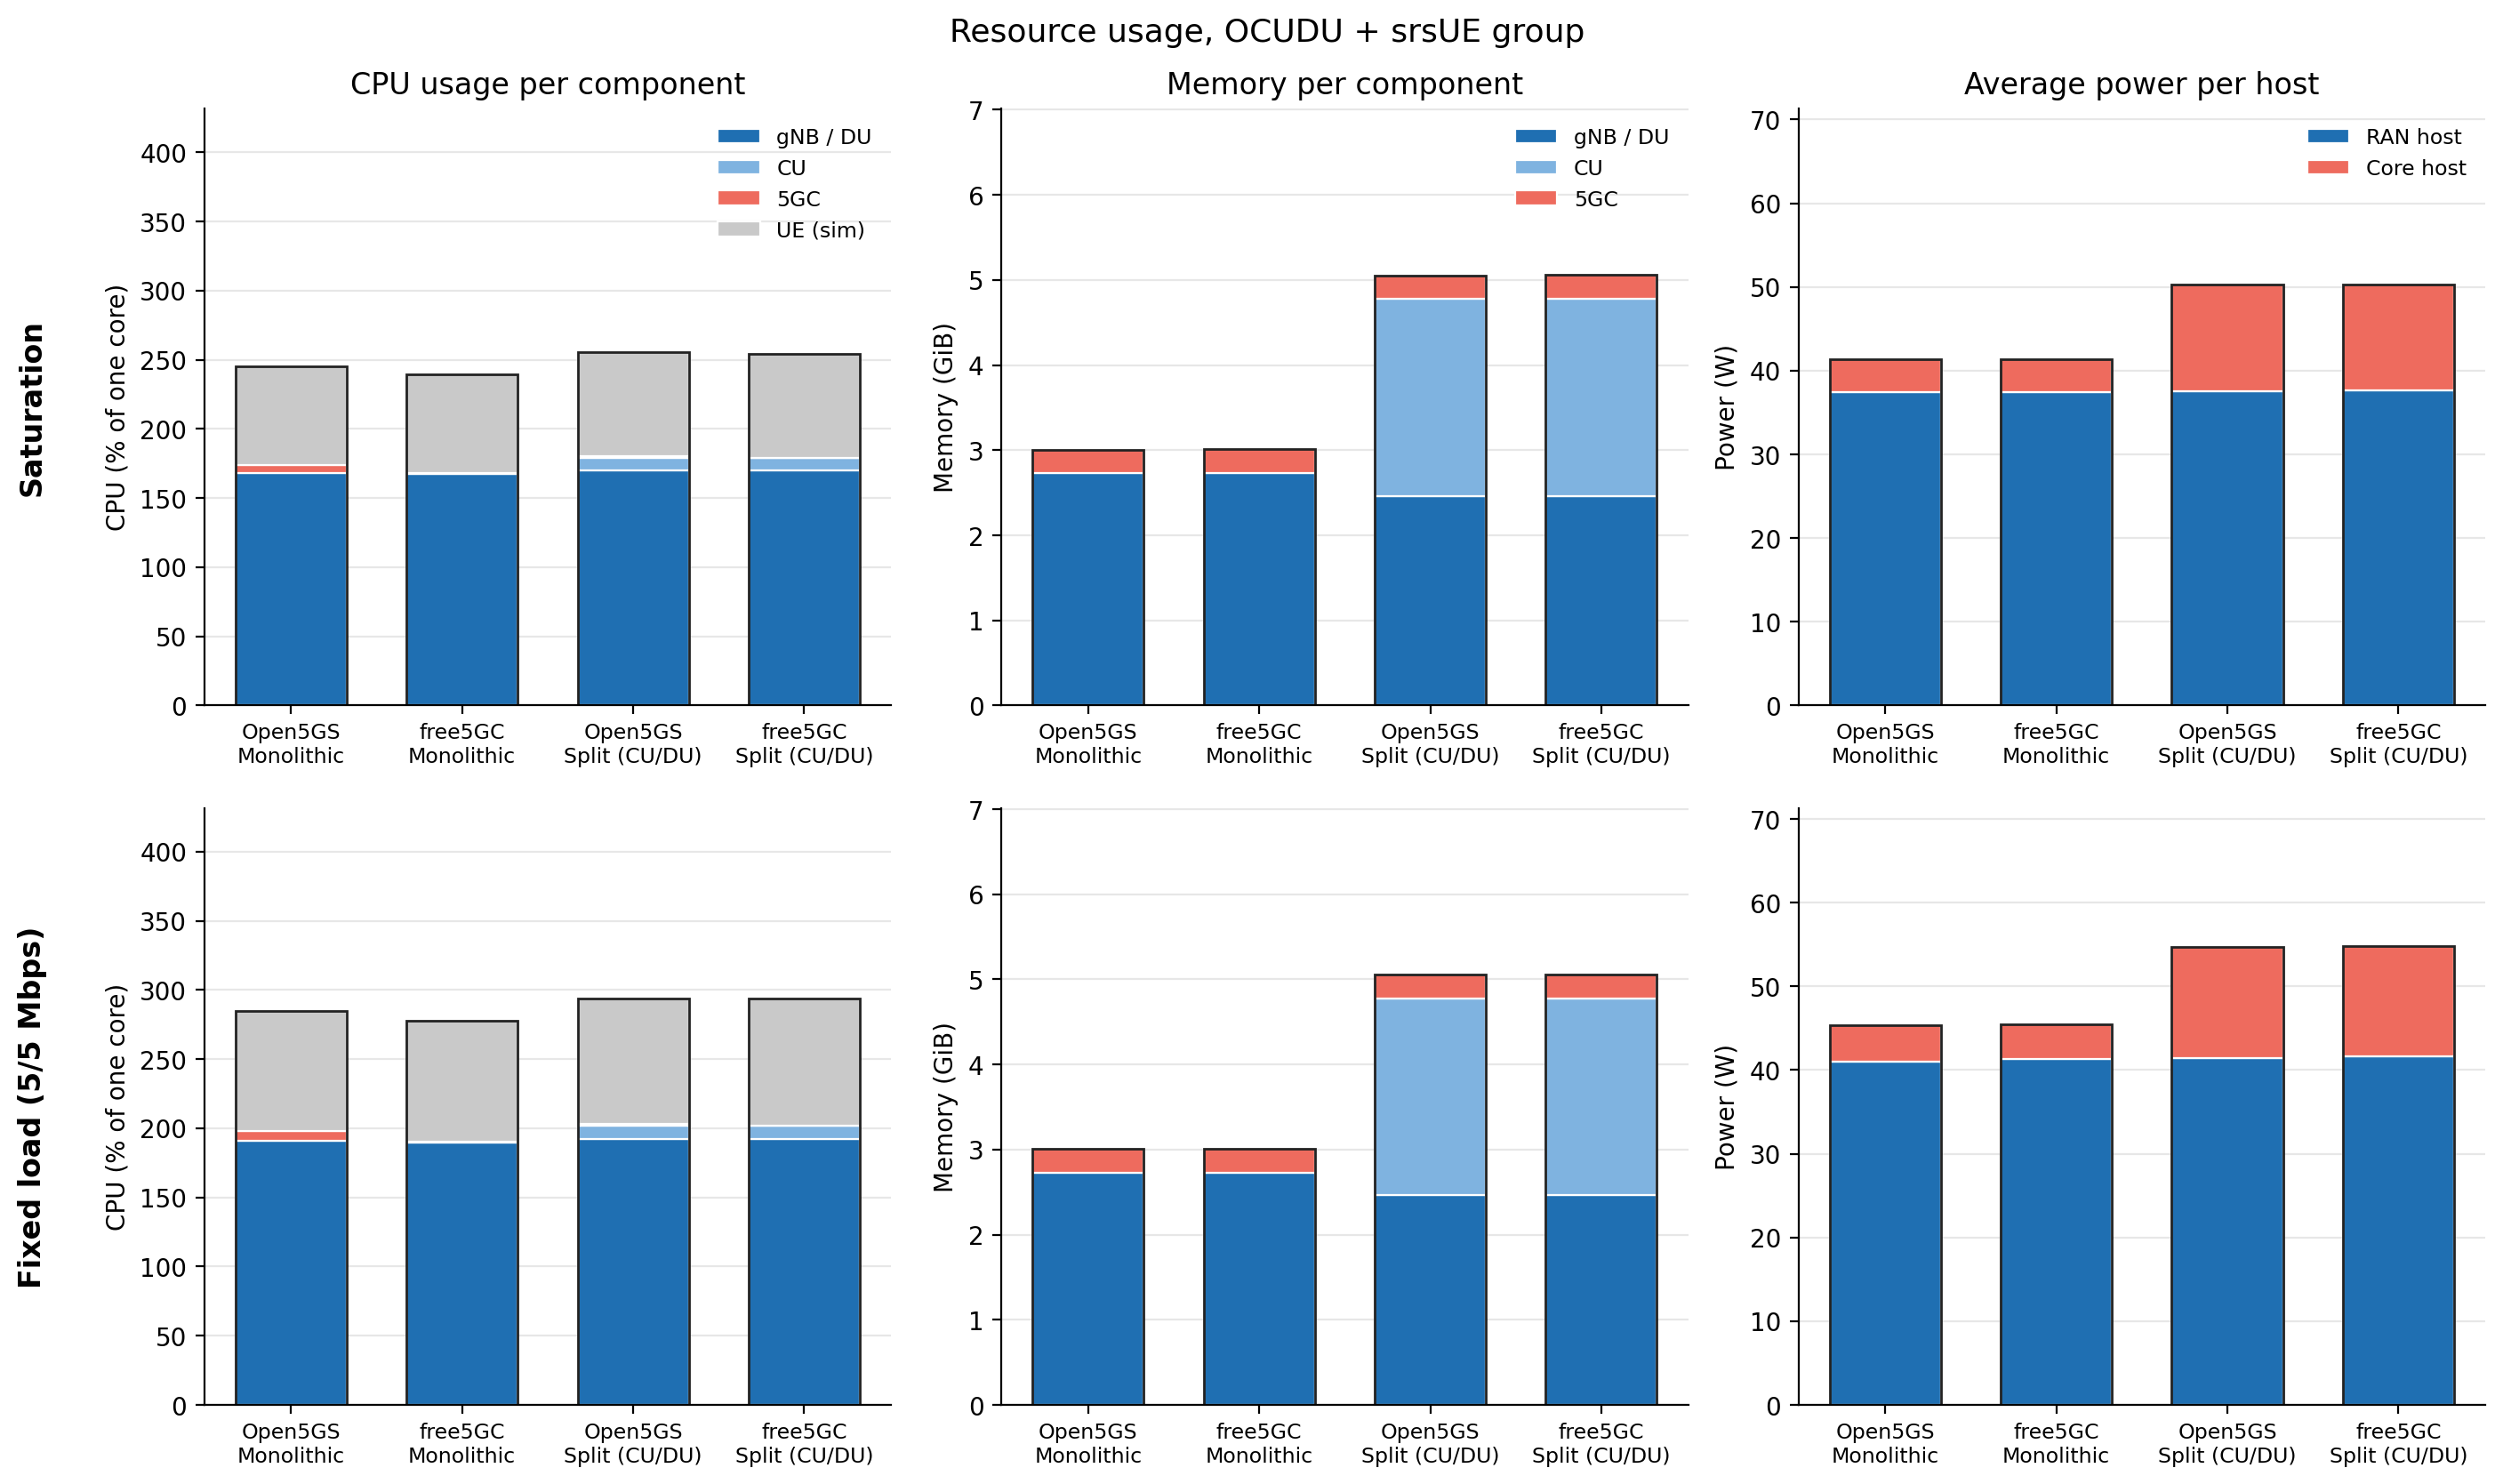

,Configuration,"Total CPU, sat. (%)","Total CPU, fixed (%)","Network mem, sat. (GiB)","Network mem, fixed (GiB)","UE mem, fixed (GiB)","Total power, sat. (W)","Total power, fixed (W)"
ID,,,,,,,,
S1,Open5GS – Monolithic,245.4,284.7,3.00,3.01,0.81,41.4,45.3
S2,free5GC – Monolithic,239.7,277.4,3.01,3.01,0.81,41.4,45.5
S3,Open5GS – Split (CU/DU),255.6,293.5,5.05,5.06,0.81,50.2,54.7
S4,free5GC – Split (CU/DU),254.5,293.6,5.06,5.06,0.81,50.3,54.8


In [5]:
ocudu_comb = plot_resources_combined("ocudu")

Saved resources_combined_oai.png and .pdf in figures


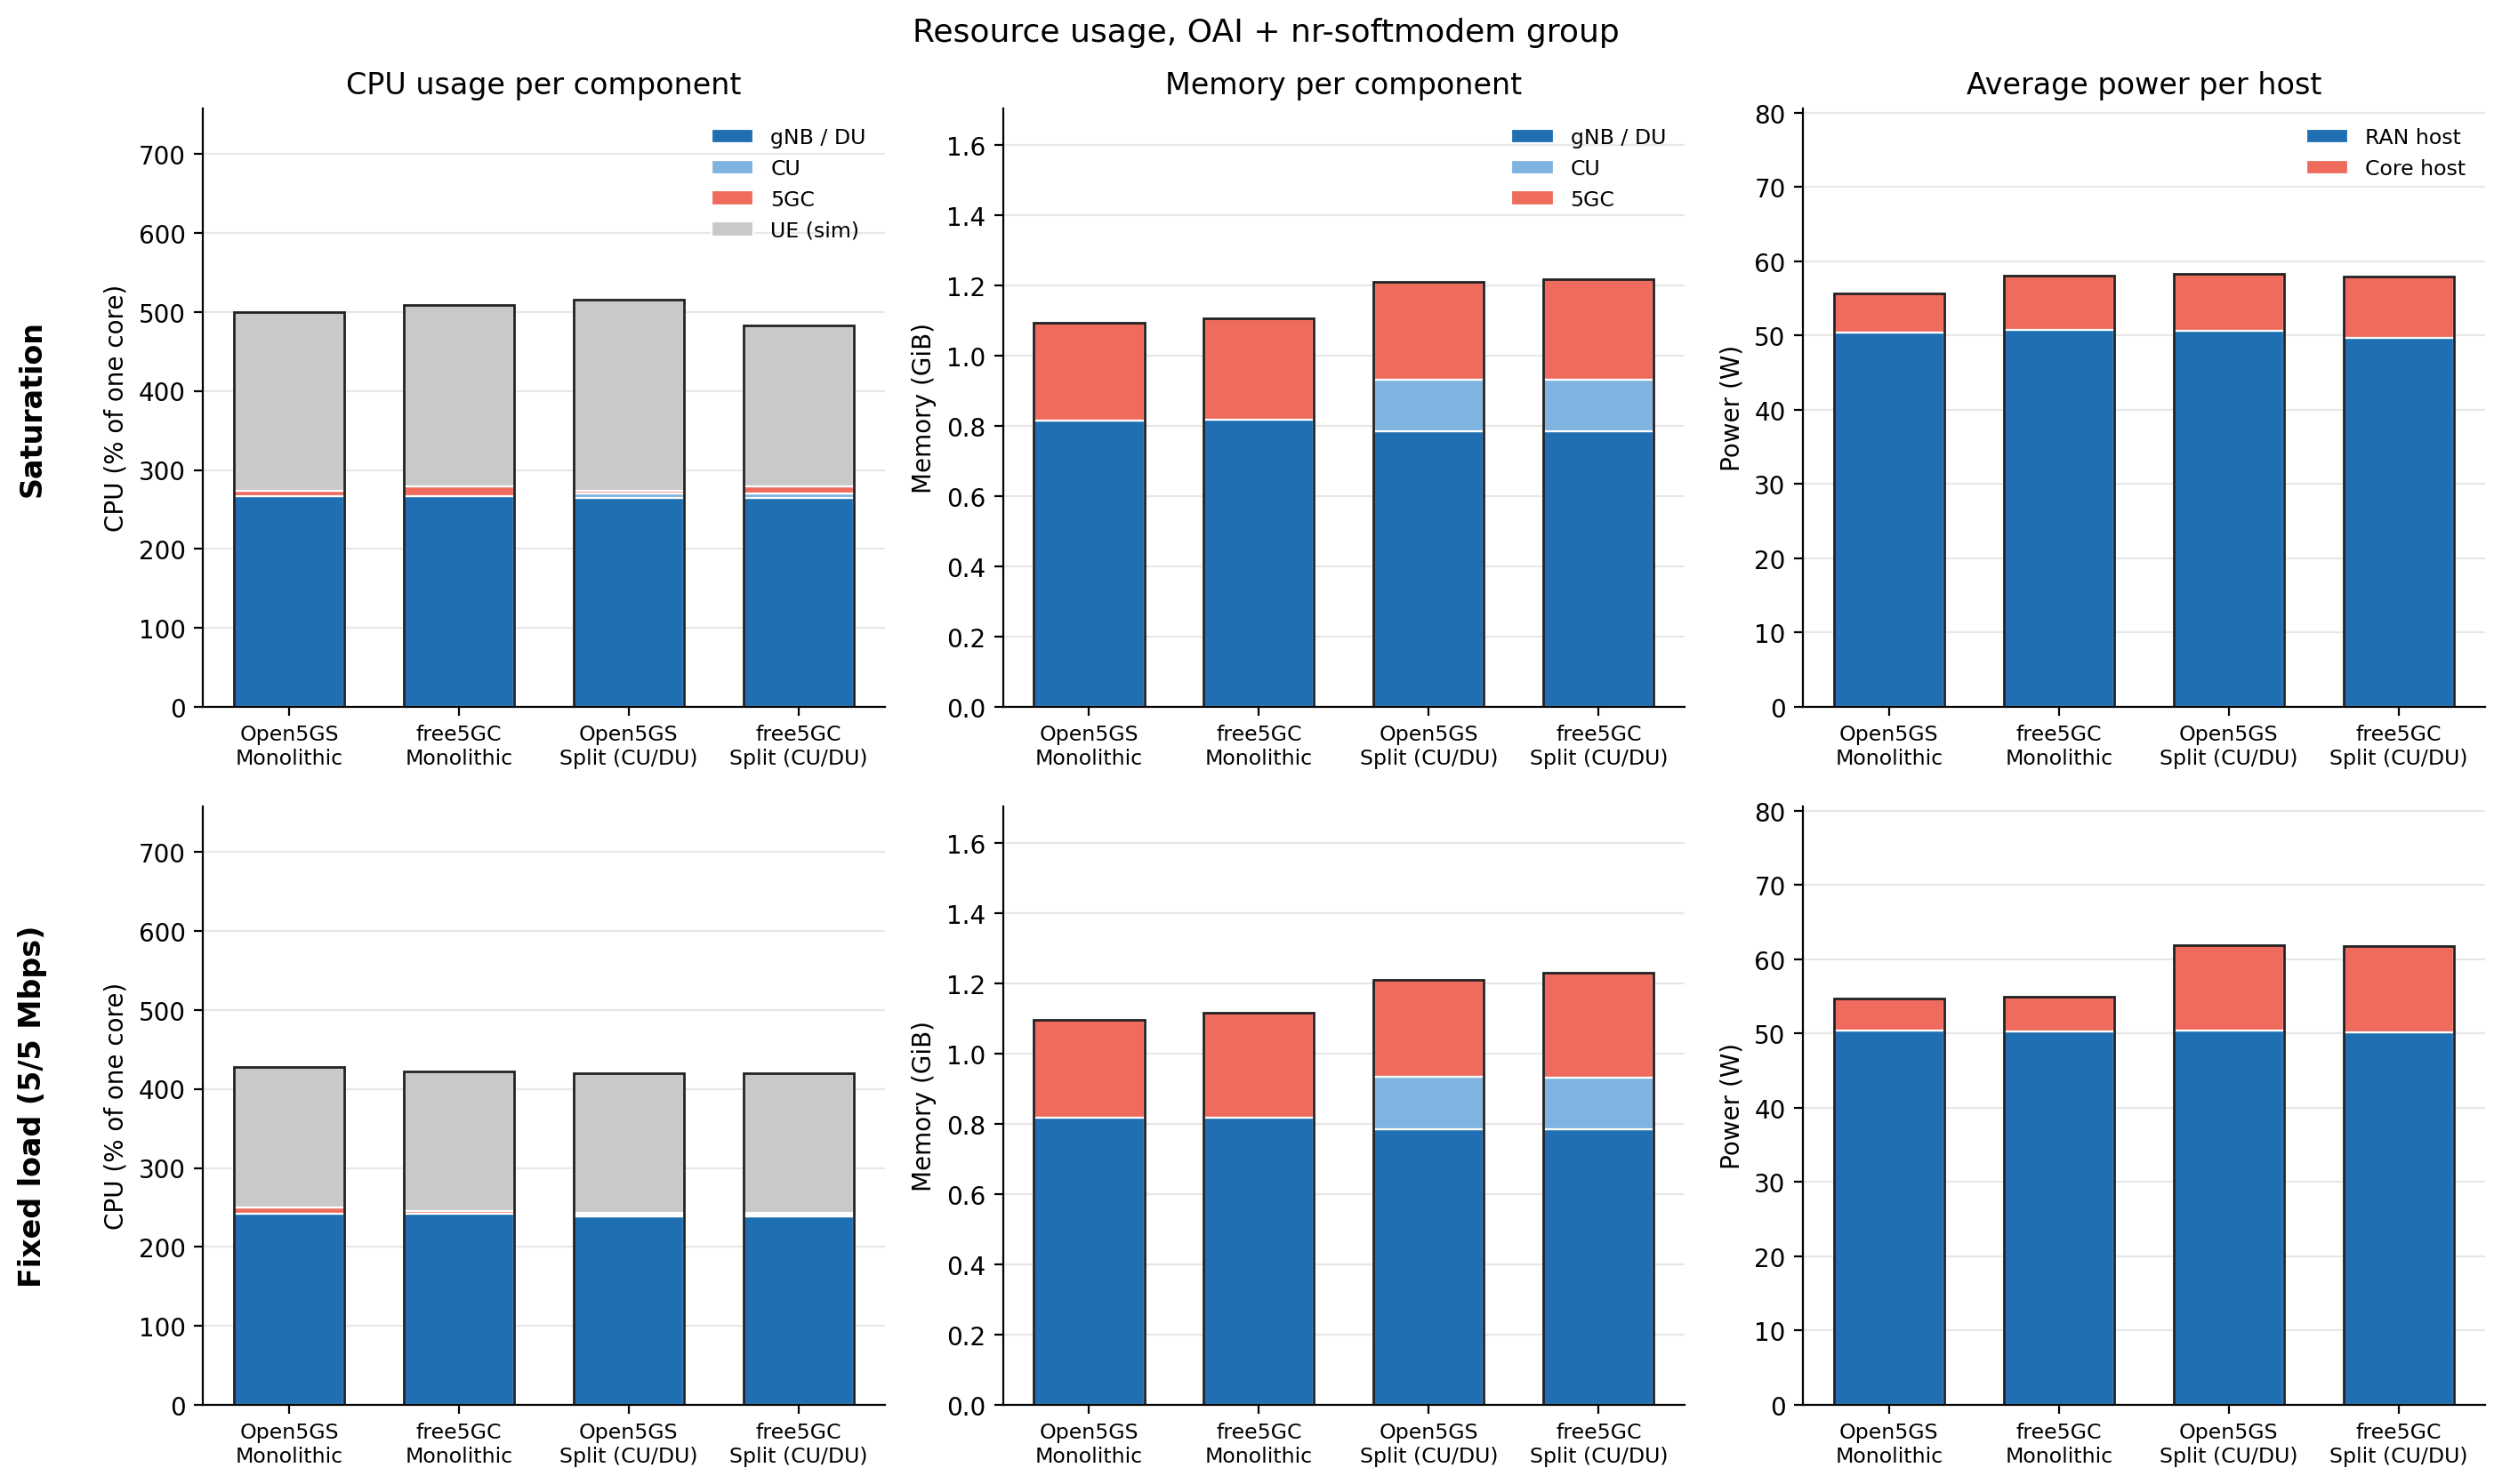

,Configuration,"Total CPU, sat. (%)","Total CPU, fixed (%)","Network mem, sat. (GiB)","Network mem, fixed (GiB)","UE mem, fixed (GiB)","Total power, sat. (W)","Total power, fixed (W)"
ID,,,,,,,,
O1,Open5GS – Monolithic,499.9,427.8,1.09,1.10,0.47,55.7,54.7
O2,free5GC – Monolithic,509.4,422.3,1.11,1.12,0.47,58.1,55.0
O3,Open5GS – Split (CU/DU),515.4,420.4,1.21,1.21,0.47,58.3,61.9
O4,free5GC – Split (CU/DU),482.5,420.5,1.22,1.23,0.47,58.0,61.8


In [6]:
oai_comb = plot_resources_combined("oai")

## Optional: save the summary tables

The fixed-load columns of this table are the "small table" for the fixed-load paragraph in your report.

In [7]:
for name, table in [("ocudu", ocudu_comb), ("oai", oai_comb)]:
    table.to_csv(OUTPUT_DIR / f"resources_combined_{name}_summary.csv")
    print(f"--- {name} ---")
    print(table.to_latex(float_format="%.2f"))

--- ocudu ---
\begin{tabular}{llrrrrrrr}
\toprule
 & Configuration & Total CPU, sat. (%) & Total CPU, fixed (%) & Network mem, sat. (GiB) & Network mem, fixed (GiB) & UE mem, fixed (GiB) & Total power, sat. (W) & Total power, fixed (W) \\
ID &  &  &  &  &  &  &  &  \\
\midrule
S1 & Open5GS – Monolithic & 245.40 & 284.70 & 3.00 & 3.01 & 0.81 & 41.40 & 45.30 \\
S2 & free5GC – Monolithic & 239.70 & 277.40 & 3.01 & 3.01 & 0.81 & 41.40 & 45.50 \\
S3 & Open5GS – Split (CU/DU) & 255.60 & 293.50 & 5.05 & 5.06 & 0.81 & 50.20 & 54.70 \\
S4 & free5GC – Split (CU/DU) & 254.50 & 293.60 & 5.06 & 5.06 & 0.81 & 50.30 & 54.80 \\
\bottomrule
\end{tabular}

--- oai ---
\begin{tabular}{llrrrrrrr}
\toprule
 & Configuration & Total CPU, sat. (%) & Total CPU, fixed (%) & Network mem, sat. (GiB) & Network mem, fixed (GiB) & UE mem, fixed (GiB) & Total power, sat. (W) & Total power, fixed (W) \\
ID &  &  &  &  &  &  &  &  \\
\midrule
O1 & Open5GS – Monolithic & 499.90 & 427.80 & 1.09 & 1.10 & 0.47 & 55.70 & 54